# Оценка уровня загрязнения атмосферы
Задание №1 из практикума "Методы исследования качества среды урбанизированных территорий" М.Ю. Глуховская, Т.А. Евстифеева:  http://elib.osu.ru/bitstream/123456789/13456/1/134262_20201201.pdf?ysclid=mcu9hv4ndo570799114

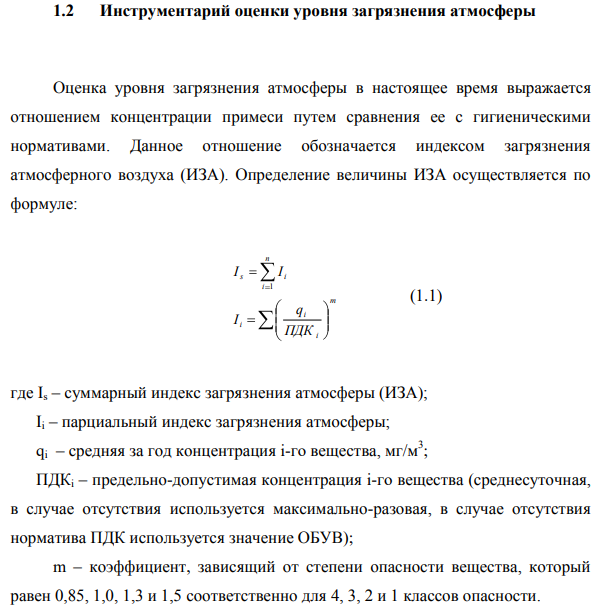

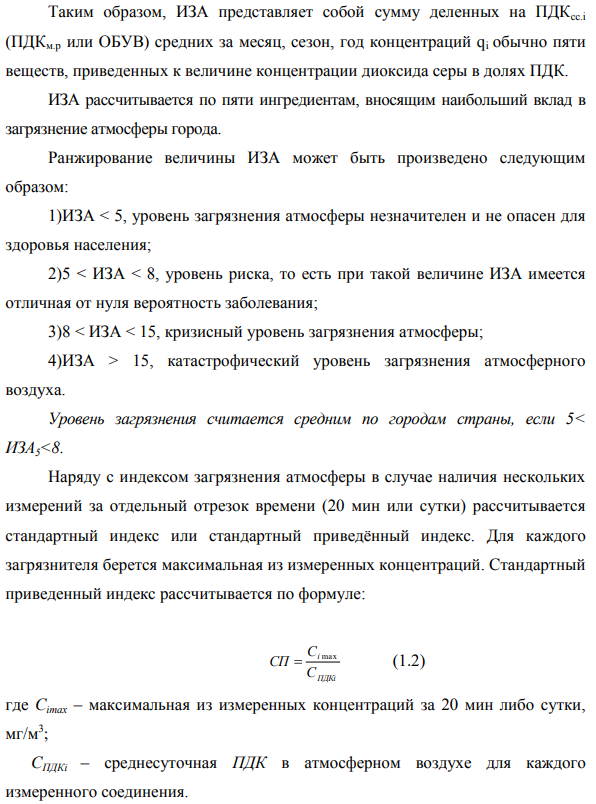

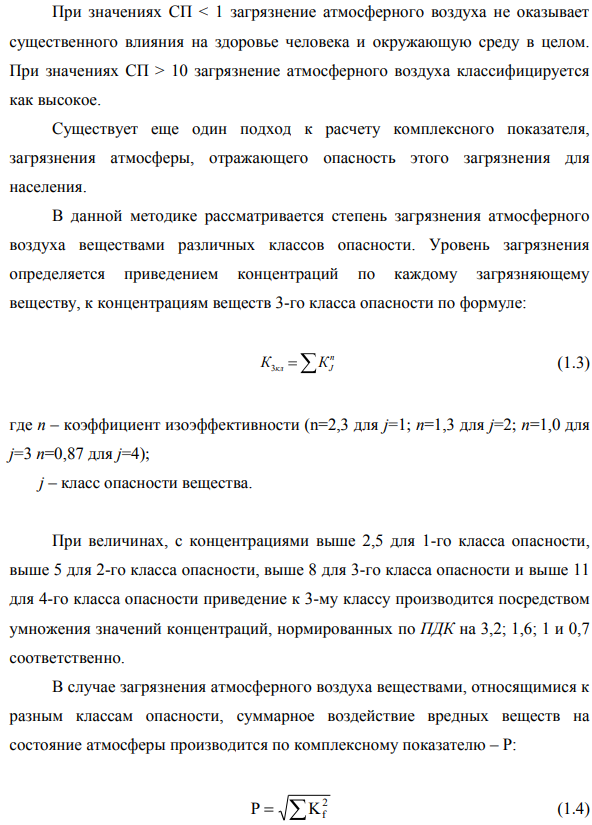

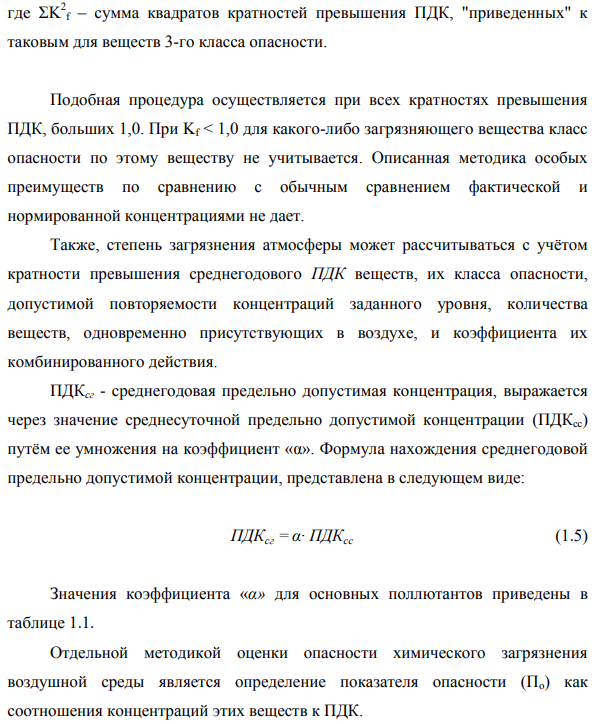

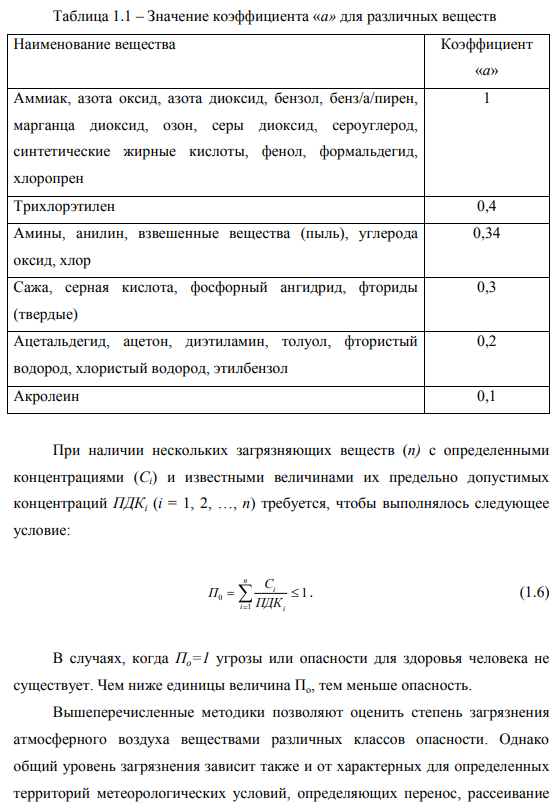

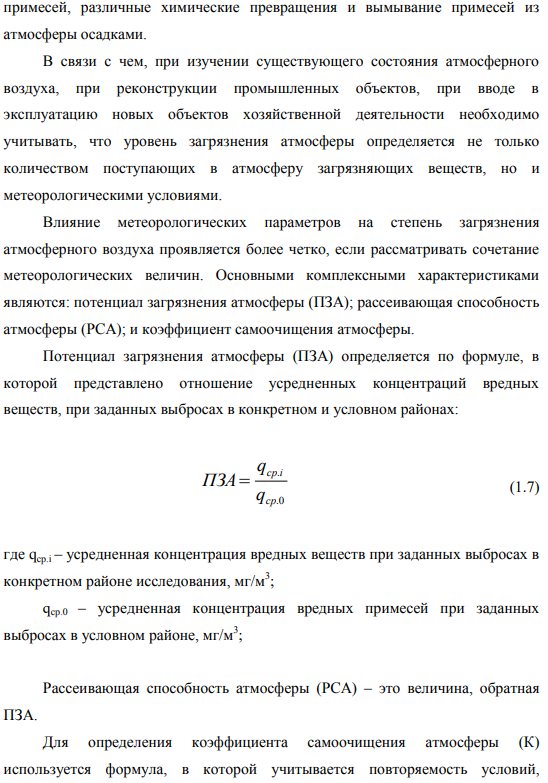

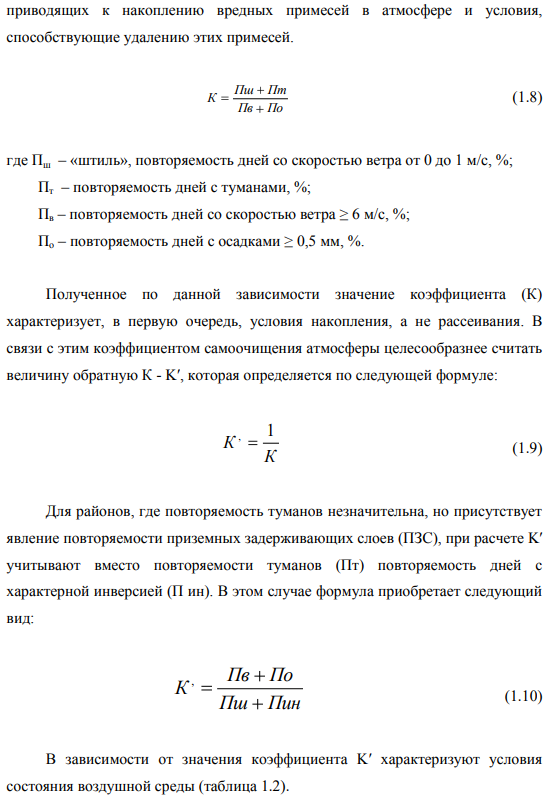

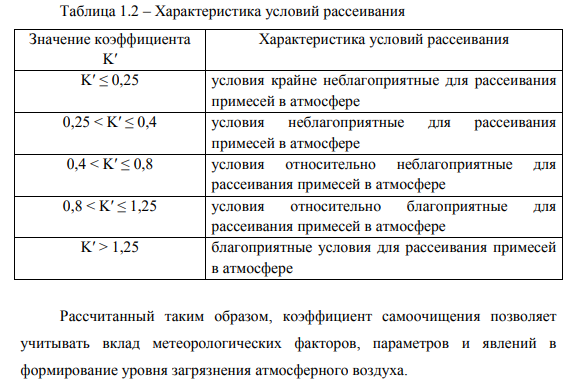

### Загрузка файлов, выделение требуемых переменных за нужный период

In [7]:
import pandas as pd
import glob

valid_files = [
    'st_01.csv', 'st_02.csv', 'st_05.csv', 'st_07.csv', 'st_09.csv',
    'st_26.csv', 'st_27.csv', 'tr_03.csv', 'tr_04.csv', 'tr_05.csv', 'tr_06.csv'
]

# Целевые столбцы
target_cols = [
    'Время',
    'Диоксид серы',
    'Оксид углерода',
    'Диоксид азота',
    'Частицы 10 мкм',
    'Частицы 2.5 мкм',
    'Температура'
]

# Загрузка и объединение
all_data = []

for file in file_paths:
    if file in valid_files:
        try:
            df = pd.read_csv(file, sep=';', usecols=lambda x: x in target_cols, encoding='windows-1251')
            df['Файл'] = file
            df['Время'] = pd.to_datetime(df['Время'], errors='coerce', dayfirst=True)
            all_data.append(df)
        except Exception as e:
            print(f"Ошибка при чтении файла {file}: {e}")

# Объединение
data = pd.concat(all_data, ignore_index=True)

# Фильтрация по 2022 году
data_2022 = data[data['Время'].dt.year == 2022].copy()

print(data_2022.head())

                Время  Диоксид серы  Оксид углерода  Диоксид азота  \
0 2022-06-01 01:39:00           NaN             0.2          0.004   
1 2022-06-01 01:59:00           NaN             0.2          0.006   
2 2022-06-01 02:19:00           NaN             0.2          0.008   
3 2022-06-01 02:39:00           NaN             0.2          0.011   
4 2022-06-01 02:59:00           NaN             0.2          0.010   

   Частицы 10 мкм  Частицы 2.5 мкм  Температура       Файл  
0           0.003            0.003         10.5  st_01.csv  
1           0.003            0.003         10.8  st_01.csv  
2           0.003            0.003         10.7  st_01.csv  
3           0.004            0.004         10.7  st_01.csv  
4           0.004            0.004         10.7  st_01.csv  


### Выполнение расчётов соответственно лабораторной работе

In [43]:
import numpy as np
# Целевые столбцы: 'Время' и основные загрязняющие вещества
target_cols = [
    'Время',
    'Диоксид серы',
    'Оксид углерода',
    'Диоксид азота',
    'Частицы 10 мкм',
    'Частицы 2.5 мкм'
]

# Найдено в интернете
danger_classes = {
    'Диоксид серы': 3,
    'Оксид углерода': 4,
    'Диоксид азота': 2,
    'Частицы 10 мкм': 3,
    'Частицы 2.5 мкм': 3
}

# Таблица с ПДК (предельно допустимыми концентрациями), мг/м³
# из СанПиН 1.2.3685-21, таблица 1.1 (https://docs.cntd.ru/document/573500115)
# Здесь хранятся ПДКсс, так как они используются для вычисления ПДКсг
PDK_ss = {
    'Диоксид серы': 0.05,
    'Оксид углерода': 3.0,
    'Диоксид азота': 0.04,
    'Частицы 10 мкм': 0.06,
    'Частицы 2.5 мкм': 0.035
}

# Коэффициенты 'm' для ИЗА (формула 1.1). (стр. 7)
m_coeffs = {1: 1.5, 2: 1.3, 3: 1.0, 4: 0.85}

# Коэффициенты изоэффективности 'n' для формулы 1.3 (K_3кл). j (класс опасности вещества): n (стр. 9)
n_coeffs = {1: 2.3, 2: 1.3, 3: 1.0, 4: 0.87}

# Коэффициенты приведения к 3-му классу опасности (для K_J и Kf)
# Эти коэффициенты применяются к нормированной концентрации (qi/ПДК) (стр. 9)
conversion_coeffs_to_class3 = {1: 3.2, 2: 1.6, 3: 1.0, 4: 0.7}

# Таблица 1.1 – Значение коэффициента «а» для различных веществ (Формула 1.5)
# Примечание: для отсутствующих в таблице веществ, может потребоваться определить alpha
# или использовать стандартное значение (например, 1, если нет специфики).
alpha_coeffs = {
    'Диоксид серы': 1.0,  # Аммиак, ... серы диоксид, ... - 1
    'Оксид углерода': 0.34, # ... углерода оксид, ... - 0.34
    'Диоксид азота': 1.0, # ... азота диоксид, ... - 1
    # Для частиц (взвешенные вещества) есть 'пыль' с alpha=0.34
    'Частицы 10 мкм': 0.34, # Взвешенные вещества (пыль)
    'Частицы 2.5 мкм': 0.34 # Взвешенные вещества (пыль)
}


# Расчёты среднегодовых и максимальных концентраций
avg_concentrations = data_2022[target_cols[1:]].mean()
max_concentrations = data_2022[target_cols[1:]].max()

summary = []
K_J_terms_for_K3kl = [] # Для формулы 1.3
Kf_squared_terms_for_P = [] # Для формулы 1.4
Ci_div_PDKi_for_Po = [] # Для формулы 1.6
Ii_for_Is = [] # Для новой реализации формулы 1.1 (Ii = (qi/ПДКi)^m)


for pollutant in avg_concentrations.index:
    # Используем PDK_ss для получения среднесуточной ПДК
    if pollutant in PDK_ss and pollutant in danger_classes:
        qi = avg_concentrations[pollutant]
        c_max = max_concentrations[pollutant]
        pdk_ss_val = PDK_ss[pollutant] # Получаем среднесуточную ПДК
        danger_class = danger_classes[pollutant]
        m = m_coeffs[danger_class] # Коэффициент 'm' для текущего вещества

        # --- Расчет ПДКсг (формула 1.5) ---
        alpha = alpha_coeffs.get(pollutant, 1.0) # Получаем альфа, по умолчанию 1.0 если нет в таблице
        pdk_sg_val = alpha * pdk_ss_val # Вычисляем среднегодовую ПДК (формула 1.5)
        
        # Теперь все расчёты, требующие ПДК, будут использовать ПДКсг
        # Для SP будем использовать pdk_ss_val.
        # А для ИЗА (qi/ПДКi) и других расчётов, использующих qi (среднегодовая), будем использовать pdk_sg_val.

        # --- Расчёт для ИЗА (формула 1.1) ---
        # Ii = (qi / ПДКсг)^m
        Ii_ratio_to_PDK_sg = qi / pdk_sg_val
        
        # Парциальный индекс Ii
        Ii_new_formula = (Ii_ratio_to_PDK_sg) ** m
        Ii_for_Is.append(Ii_new_formula)

        # --- Расчёт Стандартного показателя СП (формула 1.2) ---
        # Используем ПДКсс для СП
        SP = c_max / pdk_ss_val

        # --- Расчёт для K_3кл (формула 1.3) ---
        # K_J = (qi / ПДКсг) * коэффициент_приведения_к_3_классу
        Kj = Ii_ratio_to_PDK_sg * conversion_coeffs_to_class3[danger_class]
        n_isoeff = n_coeffs[danger_class]
        K_J_terms_for_K3kl.append(Kj ** n_isoeff)

        # --- Расчёт для комплексного показателя P (формула 1.4) ---
        # Kf - кратность превышения ПДК, приведённая к 3 классу опасности
        # Только если кратность превышения (qi/ПДКсг) > 1.0
        if Ii_ratio_to_PDK_sg > 1.0:
            Kf = Ii_ratio_to_PDK_sg * conversion_coeffs_to_class3[danger_class]
            Kf_squared_terms_for_P.append(Kf ** 2)
        else:
            Kf_squared_terms_for_P.append(0) # Если Ii <= 1, то Kf не учитывается

        # --- Расчёт для Показателя опасности По (формула 1.6) ---
        # По = Σ (Ci / ПДКi) -> здесь Ci - это qi (среднегодовая), а ПДКi - ПДКсг
        Ci_div_PDKi_for_Po.append(Ii_ratio_to_PDK_sg)


        summary.append({
            'Вещество': pollutant,
            'Среднегодовая концентрация (qi)': round(qi, 4),
            'Cмакс': round(c_max, 4),
            'ПДКсс': pdk_ss_val,
            'alpha (коэф. для ПДКсг)': alpha,
            'ПДКсг': round(pdk_sg_val, 4),
            'Класс опасности': danger_class,
            'm (ИЗА)': m,
            'qi / ПДКсг': round(Ii_ratio_to_PDK_sg, 3),
            'Ii (по формуле 1.1)': round(Ii_new_formula, 3),
            'n (изоэфф.)': n_isoeff,
            'K_J (привед. к 3 кл.)': round(Kj, 3),
            'K_J^n (для K_3кл)': round(Kj ** n_isoeff, 3),
            'Kf (для P, если qi/ПДКсг > 1)': round(Ii_ratio_to_PDK_sg * conversion_coeffs_to_class3[danger_class], 3) if Ii_ratio_to_PDK_sg > 1.0 else 0,
            'Стандартный показатель СП = Cmax / ПДКсс': round(SP, 3)
        })

summary_df = pd.DataFrame(summary)

# --- Расчёты итоговых показателей ---

# Суммарный индекс загрязнения атмосферы (ИЗА) (формула 1.1)
Is = sum(Ii_for_Is)

# Суммарный индекс K_3кл (формула 1.3)
K_3kl = sum(K_J_terms_for_K3kl)

# Комплексный показатель P (формула 1.4)
# P = sqrt(Σ(Kf^2))
P = np.sqrt(sum(Kf_squared_terms_for_P))

# Показатель опасности По (формула 1.6)
Po = sum(Ci_div_PDKi_for_Po)

print("--- Сводная таблица по загрязняющим веществам ---")
print(summary_df)

print("\n--- Итоговые показатели загрязнения ---")
# Теперь Is - это сумма Ii, где Ii = (qi/ПДКсг)^m
print(f"Суммарный индекс загрязнения атмосферы (ИЗА, формула 1.1, с использованием ПДКсг): {Is:.2f}")

# Интерпретация ИЗА (ранжирование из текста, стр. 8)
if Is < 5:
    print("Уровень загрязнения (ИЗА): незначительный и не опасен для здоровья населения.")
elif 5 <= Is < 8:
    print("Уровень загрязнения (ИЗА): уровень риска, имеется отличная от нуля вероятность заболевания.")
elif 8 <= Is < 15:
    print("Уровень загрязнения (ИЗА): кризисный уровень загрязнения атмосферы.")
else:
    print("Уровень загрязнения (ИЗА): катастрофический уровень загрязнения атмосферного воздуха.")

print(f"Индекс загрязнения, приведенный к 3-му классу опасности (K_3кл, формула 1.3): {K_3kl:.3f}")
print(f"Комплексный показатель P (формула 1.4): {P:.3f}")
print(f"Показатель опасности По (формула 1.6): {Po:.3f}")
if Po < 1:
    print("  Угрозы или опасности для здоровья человека не существует (По < 1).")
elif Po == 1:
    print("  Угрозы или опасности для здоровья человека не существует (По = 1).")
else:
    print("  Имеется угроза или опасность для здоровья человека (По > 1).")

--- Сводная таблица по загрязняющим веществам ---
          Вещество  Среднегодовая концентрация (qi)   Cмакс  ПДКсс  \
0     Диоксид серы                           0.0091   1.905  0.050   
1   Оксид углерода                           0.3418  41.028  3.000   
2    Диоксид азота                           0.0296   0.425  0.040   
3   Частицы 10 мкм                           0.0402   1.703  0.060   
4  Частицы 2.5 мкм                           0.0320   1.065  0.035   

   alpha (коэф. для ПДКсг)   ПДКсг  Класс опасности  m (ИЗА)  qi / ПДКсг  \
0                     1.00  0.0500                3     1.00       0.183   
1                     0.34  1.0200                4     0.85       0.335   
2                     1.00  0.0400                2     1.30       0.739   
3                     0.34  0.0204                3     1.00       1.970   
4                     0.34  0.0119                3     1.00       2.689   

   Ii (по формуле 1.1)  n (изоэфф.)  K_J (привед. к 3 кл.)  K_J^n (для K

### Визуализация данных с предельно допустимыми концентрациями (ПДК)

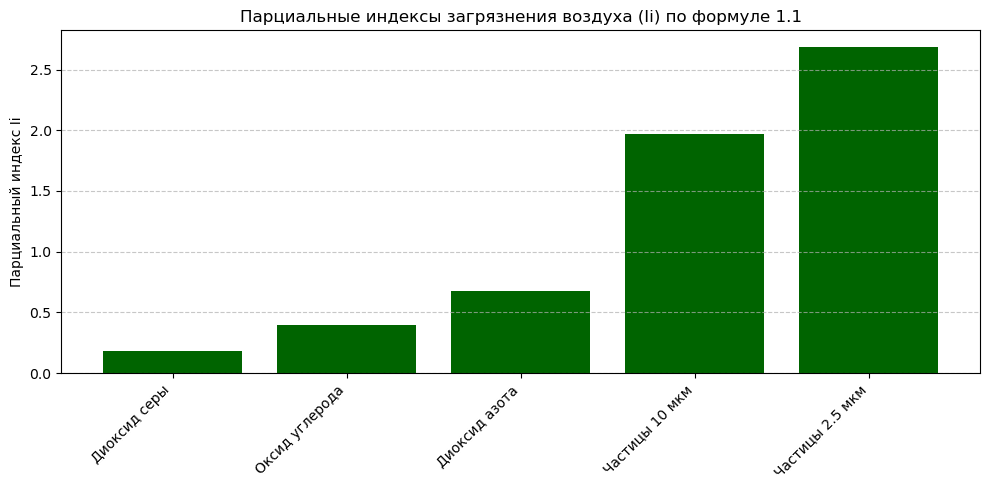

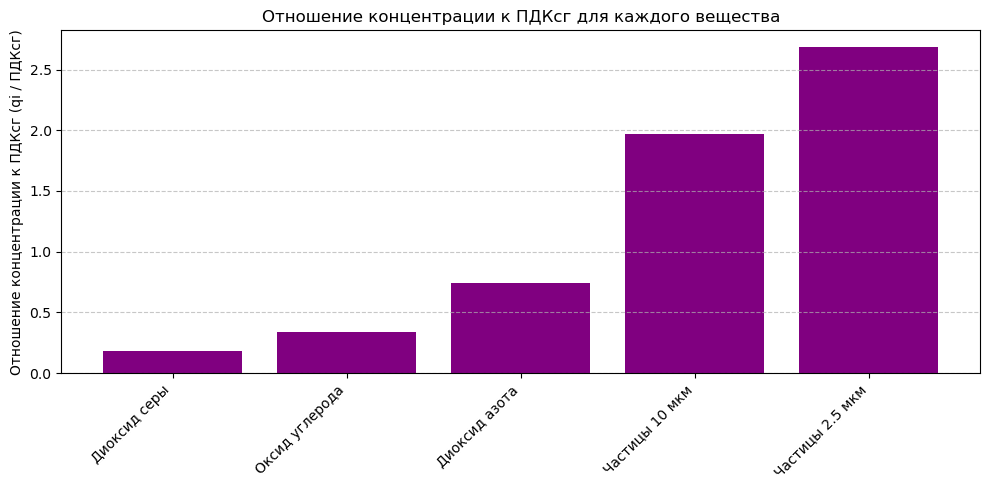

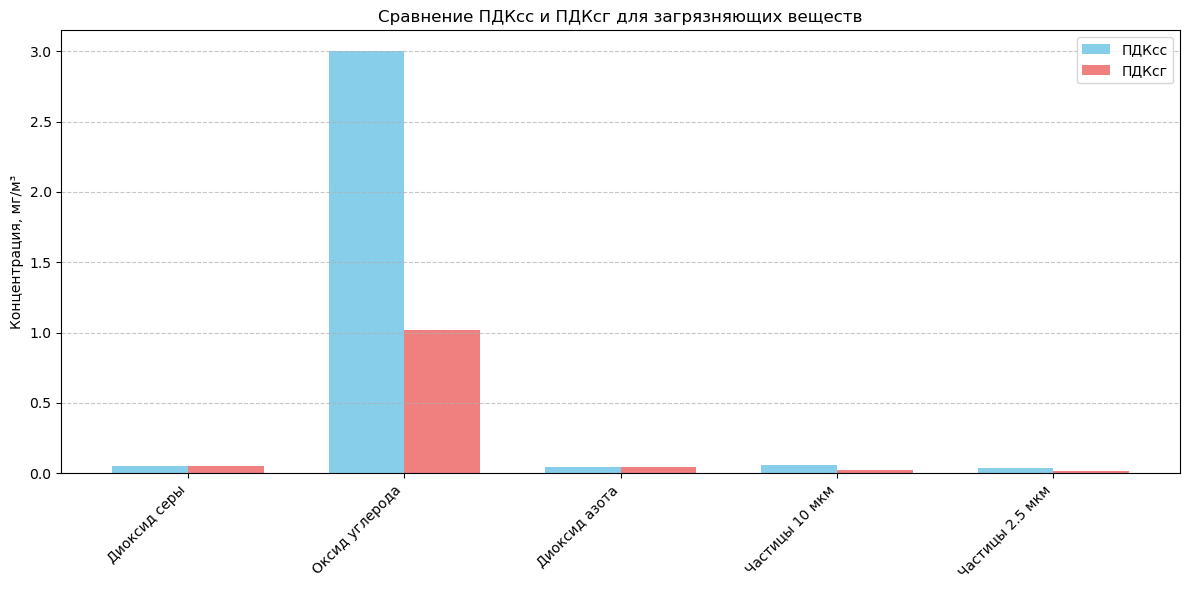

In [9]:
import matplotlib.pyplot as plt
# Визуализация парциальных индексов (Ii = (qi/ПДКсг)^m)
plt.figure(figsize=(10, 5))
plt.bar(summary_df['Вещество'], summary_df['Ii (по формуле 1.1)'], color='darkgreen')
plt.ylabel('Парциальный индекс Ii')
plt.title('Парциальные индексы загрязнения воздуха (Ii) по формуле 1.1')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Визуализация qi / ПДКсг для сравнения
plt.figure(figsize=(10, 5))
plt.bar(summary_df['Вещество'], summary_df['qi / ПДКсг'], color='purple')
plt.ylabel('Отношение концентрации к ПДКсг (qi / ПДКсг)')
plt.title('Отношение концентрации к ПДКсг для каждого вещества')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Сравнение ПДКсс и ПДКсг
plt.figure(figsize=(12, 6))
width = 0.35
x = np.arange(len(summary_df['Вещество']))

plt.bar(x - width/2, summary_df['ПДКсс'], width, label='ПДКсс', color='skyblue')
plt.bar(x + width/2, summary_df['ПДКсг'], width, label='ПДКсг', color='lightcoral')

plt.ylabel('Концентрация, мг/м³')
plt.title('Сравнение ПДКсс и ПДКсг для загрязняющих веществ')
plt.xticks(x, summary_df['Вещество'], rotation=45, ha='right')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Визуализация временных рядов концентраций с ПДК


--- Визуализация временных рядов концентраций с ПДК ---


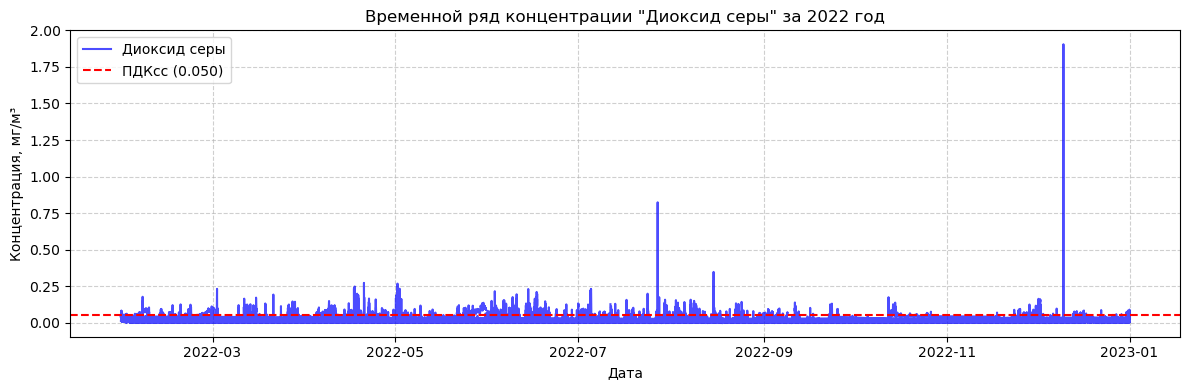

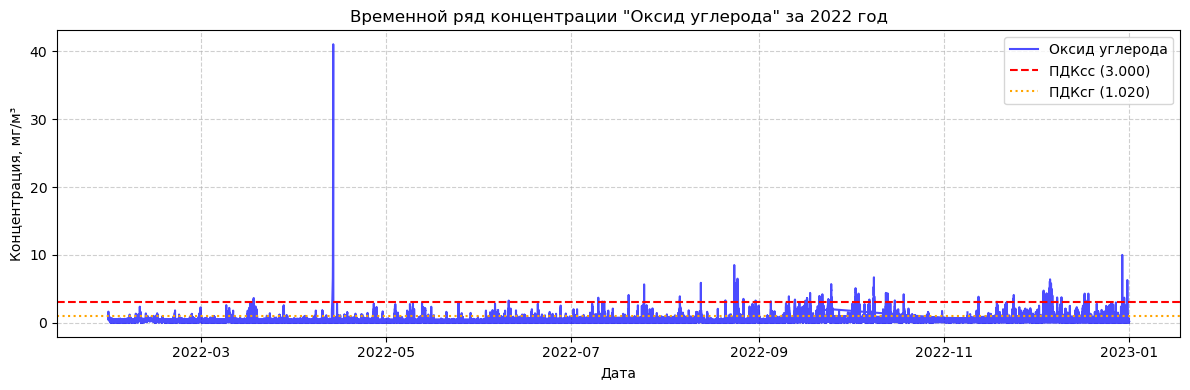

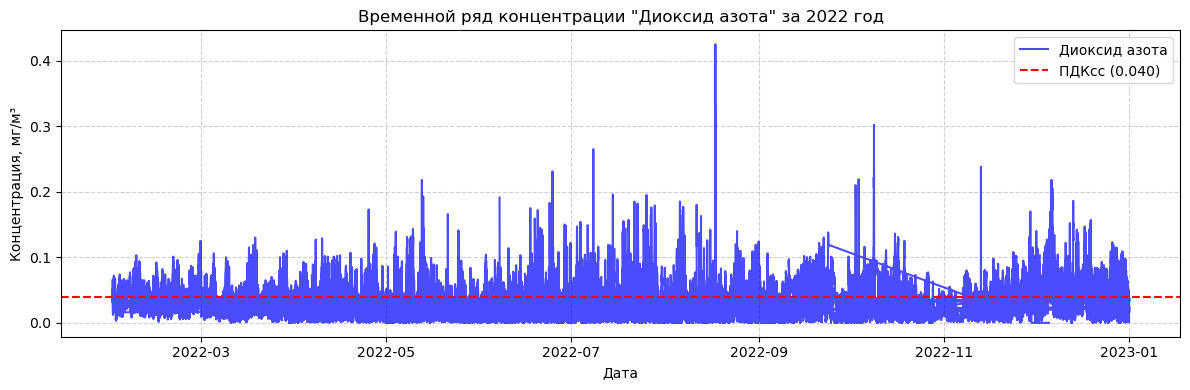

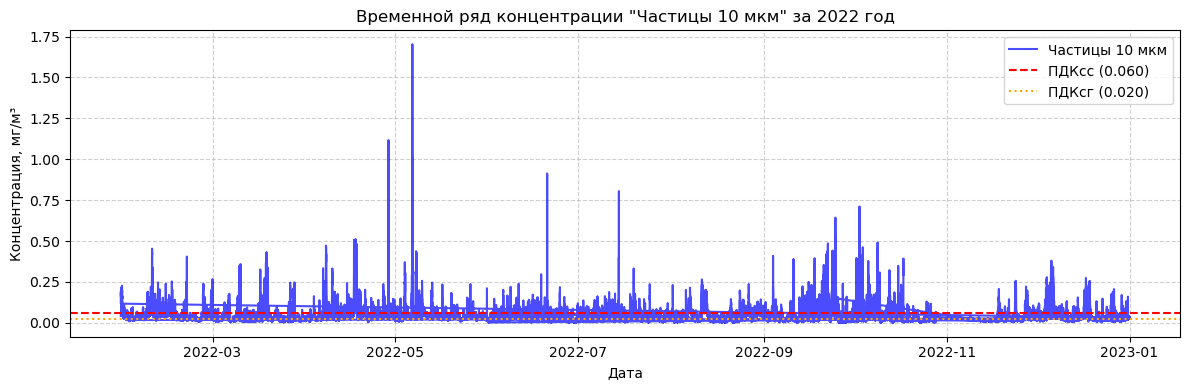

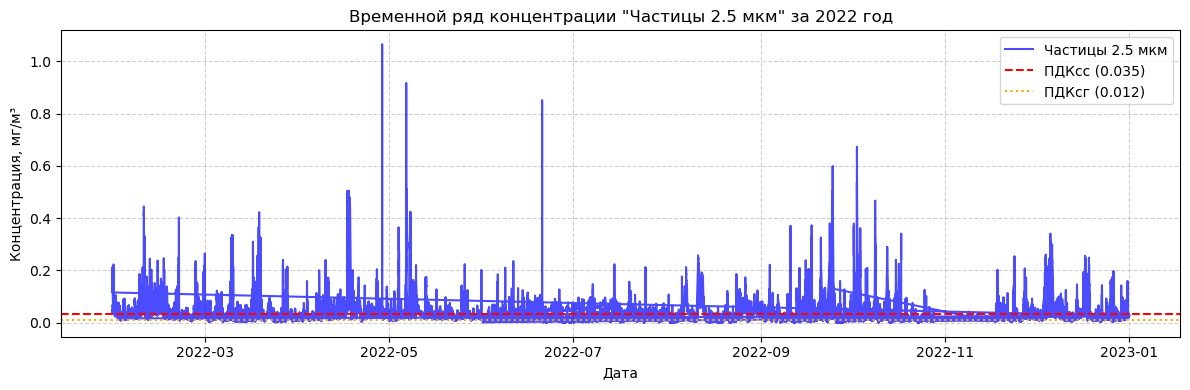

In [10]:
print("\n--- Визуализация временных рядов концентраций с ПДК ---")

# Список загрязняющих веществ, для которых хотим построить графики
# Можно взять из target_cols, исключив 'Время'
pollutants_for_time_series = target_cols[1:]

for pollutant in pollutants_for_time_series:
    if pollutant in PDK_ss: # Проверяем, есть ли ПДК для этого вещества
        plt.figure(figsize=(12, 4))
        
        # Сам временной ряд
        plt.plot(data_2022['Время'], data_2022[pollutant], label=pollutant, color='blue', alpha=0.7)
        
        # Линия ПДКсс
        pdk_val_ss = PDK_ss[pollutant]
        plt.axhline(pdk_val_ss, color='red', linestyle='--', label=f'ПДКсс ({pdk_val_ss:.3f})')

        # Линия ПДКсг (если она отличается от ПДКсс и используется для расчетов среднегодовых)
        # Это будет особенно актуально для веществ с alpha < 1
        alpha_val = alpha_coeffs.get(pollutant, 1.0)
        pdk_val_sg = alpha_val * pdk_val_ss
        if pdk_val_sg != pdk_val_ss:
             plt.axhline(pdk_val_sg, color='orange', linestyle=':', label=f'ПДКсг ({pdk_val_sg:.3f})')


        plt.title(f'Временной ряд концентрации "{pollutant}" за 2022 год')
        plt.xlabel('Дата')
        plt.ylabel('Концентрация, мг/м³')
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.tight_layout()
        plt.show()
    else:
        print(f"Внимание: Для вещества '{pollutant}' не найдено значение ПДКсс для построения графика временного ряда.")

### Расчёт метеорологических показателей

In [50]:
import pandas as pd
import numpy as np

def calculate_meteorological_indices(file_path='Weather_data_2022.csv'):
    Psh, Pt, Pv, Po_osadki, Pin = np.nan, np.nan, np.nan, np.nan, np.nan
    K, K_prime, K_prime_inv = np.nan, np.nan, np.nan

    try:
        meteo_df = pd.read_csv(
            file_path,
            sep=';',
            encoding='utf-8',
            engine='python',
            index_col=False, # Не использовать первую колонку как индекс
            parse_dates=['Местное время в Омске'], # Явно указать колонку для парсинга дат
            dayfirst=True # Указываем, что день идёт перед месяцем
        )

        # Фильтрация данных по 2022 году
        # Отфильтровываем строки, где дата не является NaT, перед фильтрацией по году
        meteo_df_2022 = meteo_df[meteo_df['Местное время в Омске'].notna() & 
                                 (meteo_df['Местное время в Омске'].dt.year == 2022)].copy()

        print("\n--- Отладочная информация после фильтрации по 2022 году ---")
        print(f"Количество строк в meteo_df_2022: {meteo_df_2022.shape[0]}")
        if not meteo_df_2022.empty:
            print(f"Первая дата в meteo_df_2022: {meteo_df_2022['Местное время в Омске'].min()}")
            print(f"Последняя дата в meteo_df_2022: {meteo_df_2022['Местное время в Омске'].max()}")
        
        if meteo_df_2022.empty:
            print(f"В файле '{file_path}' нет данных за 2022 год или столбец даты/времени некорректен.")
            return Psh, Pt, Pv, Po_osadki, Pin, K, K_prime, K_prime_inv

        total_days_2022 = meteo_df_2022['Местное время в Омске'].dt.date.nunique()
        print(f"Общее количество уникальных дней в 2022 году: {total_days_2022}")

        # Штиль (DD == "Штиль" или Ff == 0)
        meteo_df_2022['Ff_numeric'] = pd.to_numeric(meteo_df_2022['Ff'], errors='coerce')
        days_with_calm = meteo_df_2022[(meteo_df_2022['DD'] == 'Штиль') | (meteo_df_2022['Ff_numeric'] == 0)].drop_duplicates(subset='Местное время в Омске').shape[0]
        Psh = (days_with_calm / total_days_2022) * 100 if total_days_2022 > 0 else 0

        # Туманы (наличие ключевых слов в WW, W1, W2)
        meteo_df_2022['Weather_Description'] = meteo_df_2022['WW'].fillna('') + ' ' + meteo_df_2022['W1'].fillna('') + ' ' + meteo_df_2022['W2'].fillna('')
        days_with_fog = meteo_df_2022[meteo_df_2022['Weather_Description'].str.contains('туман', case=False, na=False)].drop_duplicates(subset='Местное время в Омске').shape[0]
        Pt = (days_with_fog / total_days_2022) * 100 if total_days_2022 > 0 else 0

        # Скорость ветра >= 6 м/с
        days_with_strong_wind = meteo_df_2022[meteo_df_2022['Ff_numeric'] >= 6].drop_duplicates(subset='Местное время в Омске').shape[0]
        Pv = (days_with_strong_wind / total_days_2022) * 100 if total_days_2022 > 0 else 0

        # Осадки >= 0.5 мм (поиск по описанию)
        days_with_precipitation = meteo_df_2022[meteo_df_2022['Weather_Description'].str.contains('дождь|снег|морось|ливень|осадки', case=False, na=False)].drop_duplicates(subset='Местное время в Омске').shape[0]
        Po = (days_with_precipitation / total_days_2022) * 100 if total_days_2022 > 0 else 0

        # Коэффициент самоочищения атмосферы (K, формула 1.8)
        K = (Psh + Pt) / (Pv + Po) if (Pv + Po) != 0 else np.nan

        # K' (формула 1.9)
        K_prime = 1 / K if K != 0 and not np.isnan(K) else np.nan

        return Psh, Pt, Pv, Po, K, K_prime, meteo_df_2022
    
    except FileNotFoundError:
        print(f"Ошибка: Файл '{file_path}' не найден. Убедитесь, что файл находится в той же директории или указан полный путь.")
        return np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan
    except pd.errors.ParserError as e:
        print(f"Ошибка парсинга файла '{file_path}': {e}. Проверьте правильность разделителя (sep=';') и согласованность количества столбцов в файле. Возможно, есть 'лишние' кавычки или другие нестандартные символы.")
        return np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan
    except KeyError as e:
        print(f"Ошибка: Отсутствует ожидаемый столбец {e} в файле '{file_path}'. Убедитесь, что названия столбцов в файле точно соответствуют используемым в коде.")
        return np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan
    except Exception as e:
        print(f"Произошла непредвиденная ошибка при обработке метеорологического файла '{file_path}': {e}")
        return np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan

(Psh, Pt, Pv, Po, K, K_prime, meteo_df_2022) = calculate_meteorological_indices('Weather_data_2022.csv')

print("\n--- Метеорологические показатели ---")
if not np.isnan(Psh):
    print(f"Повторяемость дней со штилем (Psh, %): {Psh:.2f}")
    print(f"Повторяемость дней с туманами (Pt, %): {Pt:.2f}")
    print(f"Повторяемость дней со скоростью ветра >= 6 м/с (Pv, %): {Pv:.2f}")
    print(f"Повторяемость дней с осадками >= 0.5 мм (Po, %): {Po:.2f}")

    print(f"Коэффициент самоочищения атмосферы (К, формула 1.8): {K:.3f}")
    print(f"Коэффициент K' (обратный K, формула 1.9): {K_prime:.3f}")

    # Интерпретация K' (таблица 1.2)
    if K_prime is not np.nan:
        if K_prime <= 0.25:
            print("  Характеристика условий рассеивания (по K'): крайне неблагоприятные.")
        elif 0.25 < K_prime <= 0.4:
            print("  Характеристика условий рассеивания (по K'): неблагоприятные.")
        elif 0.4 < K_prime <= 0.8:
            print("  Характеристика условий рассеивания (по K'): относительно неблагоприятные.")
        elif 0.8 < K_prime <= 1.25:
            print("  Характеристика условий рассеивания (по K'): относительно благоприятные.")
        else:
            print("  Характеристика условий рассеивания (по K'): благоприятные.")
else:
    print("Метеорологические показатели не могут быть рассчитаны из-за отсутствия или ошибок в файле 'Weather_data_2022.csv'.")


--- Отладочная информация после фильтрации по 2022 году ---
Количество строк в meteo_df_2022: 2918
Первая дата в meteo_df_2022: 2022-01-01 00:00:00
Последняя дата в meteo_df_2022: 2022-12-31 21:00:00
Общее количество уникальных дней в 2022 году: 365

--- Метеорологические показатели ---
Повторяемость дней со штилем (Psh, %): 45.48
Повторяемость дней с туманами (Pt, %): 24.66
Повторяемость дней со скоростью ветра >= 6 м/с (Pv, %): 21.10
Повторяемость дней с осадками >= 0.5 мм (Po, %): 233.97
Коэффициент самоочищения атмосферы (К, формула 1.8): 0.275
Коэффициент K' (обратный K, формула 1.9): 3.637
  Характеристика условий рассеивания (по K'): благоприятные.
